# Empirical Orthogonal Function (EOF) Analysis of Sea Surface Temperature Anomalies (ERSSTv5)

### Theoretical & Practical Guide
**Reference:** *A Manual for EOF and SVD analyses of Climatic Data* (`docs/eof.pdf`)  
**Authors:** H. Björnsson and S. A. Venegas (Department of Atmospheric and Oceanic Sciences & Centre for Climate and Global Change Research, McGill University)

---

## 1. Overview and Objectives
In climate and geophysical sciences, data sets often span high-dimensional spatial domains observed over long time intervals. **Empirical Orthogonal Function (EOF)** analysis—also known as **Principal Component Analysis (PCA)**—is the primary tool used to decompose the spatiotemporal variability of a single geophysical scalar field into:
1. **Spatial patterns (EOFs / eigenvectors):** Orthogonal spatial modes representing standing oscillations or centers of action.
2. **Temporal expansion coefficients (Principal Components / PCs):** Mutually uncorrelated time series indicating how each spatial pattern evolves over time.
3. **Eigenvalues:** Measures of the variance explained by each orthogonal mode.

In this notebook, we apply the mathematical formulations and MATLAB workflows presented in the manual to the **NOAA Extended Reconstructed Sea Surface Temperature version 5 (ERSSTv5)** annual anomaly dataset (`data/ERSST_AnoAnn.nc`).

### Key Workflow Steps:
1. **Data Ingestion & Exploration:** Load and inspect ERSSTv5 annual SST anomalies spanning 1880–2020.
2. **Matrix Construction ($S$-Mode):** Format 2D spatial maps across time into an $n \times p$ matrix ($n$ observation times $\times p$ spatial points) and center each column (as in MATLAB `F = detrend(M, 0)`).
3. **Area Weighting:** Apply cosine-of-latitude weighting $\sqrt{\cos(\phi)}$ to account for converging meridians on a spherical grid.
4. **EOF Decomposition:**
   - **Method A:** Direct Singular Value Decomposition (SVD) of the data matrix ($F = U \Sigma V^T$, Section 2.3.1).
   - **Method B:** Dual Covariance / Sample-Space method ($L = F F^T$, Section 4.2.1) designed for computationally intensive cases where spatial points exceed temporal points ($p \gg n$).
5. **Variance Explained & North's Rule of Thumb:** Compute percentage variance explained and evaluate sampling errors using North et al. (1982) (§4.3.2).
6. **Visualization:** Plot leading spatial EOF patterns (regression maps in $^{\circ}\mathrm{C}$) and PC time series (1880–2020).
7. **Homogeneous Correlation & Local Variance Maps:** Compute and map correlation coefficients ($r$) and local variance explained ($r^2$) as detailed in §4.1.
8. **Rotated EOFs (Varimax Rotation):** Implement the MATLAB Varimax algorithm from Appendix A to demonstrate how rotation localizes regional climate modes.


---
## 2. Setup & Library Imports
We import standard scientific Python packages: `xarray` for NetCDF I/O, `numpy` and `scipy` for linear algebra and statistics, `matplotlib` for plotting, and `cartopy` for map projections and coastline rendering.


In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings
warnings.filterwarnings('ignore')

# Set figure aesthetics
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120


---
## 3. Loading and Inspecting the ERSSTv5 Dataset
We open `ERSST_AnoAnn.nc` and inspect its dimensions, variables, and temporal range.


In [2]:
# Open NetCDF dataset
import os
nc_candidates = ['../data/ERSST_AnoAnn.nc', 'data/ERSST_AnoAnn.nc', 'ERSST_AnoAnn.nc']
nc_file = next((f for f in nc_candidates if os.path.exists(f)), 'data/ERSST_AnoAnn.nc')
ds = xr.open_dataset(nc_file)
print(ds)

# Extract coordinates and data
lats = ds['lat'].values
lons = ds['lon'].values
time_coords = ds['time'].values
years = np.array([t.year for t in time_coords])

# SST anomaly array: squeeze out the single vertical level dimension (lev: 1)
# Resulting shape: (n_time, n_lat, n_lon)
ssta_3d = ds['ssta'].values.squeeze()

print(f"\nDataset Dimensions: {ssta_3d.shape[0]} years ({years[0]}-{years[-1]}), {len(lats)} latitudes, {len(lons)} longitudes")


<xarray.Dataset>
Dimensions:    (time: 141, bnds: 2, lon: 180, lat: 89, lev: 1)
Coordinates:
  * time       (time) object 1880-06-16 00:00:00 ... 2020-06-30 00:00:00
  * lon        (lon) float64 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
  * lat        (lat) float64 -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lev        (lev) float64 0.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object ...
    ssta       (time, lev, lat, lon) float32 ...
Attributes: (12/41)
    CDI:                        Climate Data Interface version 1.9.9rc1 (http...
    Conventions:                CF-1.6, ACDD-1.3
    history:                    Wed Nov 18 09:12:27 2026: cdo -yearmean -selv...
    source:                     In situ data: ICOADS R3.0 before 2015, NCEP i...
    institution:                NOAA/NESDIS/NCEI/CCOG
    metadata_link:              https://doi.org/10.7289/V5T72FNM
    ...                         ...
    instrument:                 Convent

### Visualizing a Sample Annual SST Anomaly Field
Let's inspect the SST anomaly field for a prominent climate year, such as the major El Niño year of **2016**.


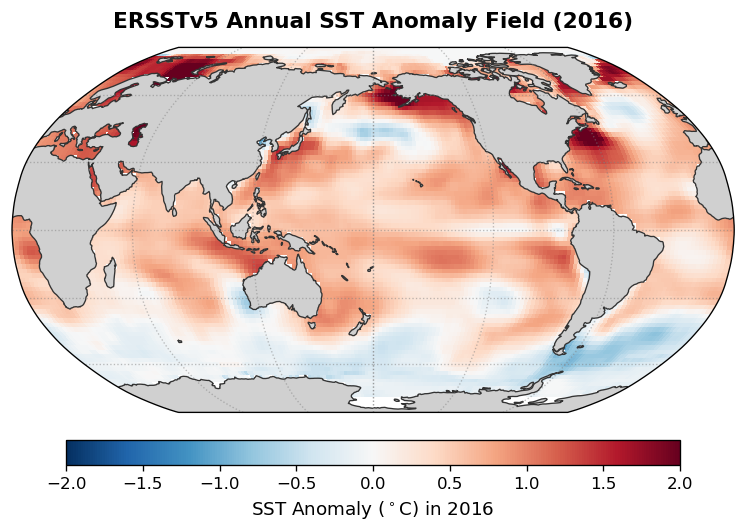

In [3]:
sample_year = 2016
idx_sample = np.where(years == sample_year)[0][0]

fig = plt.figure(figsize=(11, 5))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson(central_longitude=180))

# Mesh plot with Robinson projection
mesh = ax.pcolormesh(
    lons, lats, ssta_3d[idx_sample],
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r', vmin=-2.0, vmax=2.0, shading='auto'
)
ax.coastlines(resolution='110m', color='#333333', linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='#d0d0d0', zorder=1)
ax.gridlines(draw_labels=False, linestyle=':', color='gray', alpha=0.5)

cbar = plt.colorbar(mesh, orientation='horizontal', pad=0.06, shrink=0.6, aspect=25)
cbar.set_label(f'SST Anomaly ($^\circ$C) in {sample_year}', fontsize=11)
ax.set_title(f'ERSSTv5 Annual SST Anomaly Field ({sample_year})', fontsize=13, fontweight='bold', pad=12)
plt.show()


---
## 4. Matrix Formulation ($S$-Mode) & Preprocessing

As described in **Section 1.2** of the manual:
- Each map at time $t_j$ is arranged as a row vector of length $p$.
- The data matrix $F$ has shape $n \times p$, where $n = 141$ years and $p$ is the number of spatial observation points.
- Missing values (e.g., land grid points and regions with persistent ice) must be masked out to obtain valid ocean points.

### Preprocessing Steps:
1. **Masking:** Identify all grid points with valid, non-zero variance ocean observations over all time steps.
2. **Centering:** In MATLAB, this was done via `F = detrend(M, 0);`, which subtracts the temporal mean from each column (grid point).
3. **Area Weighting:** On a regular latitude-longitude grid, grid cell areas decrease towards the poles as $\cos(\phi)$. To prevent high-latitude grid boxes from exerting disproportionate mathematical weight, we multiply each grid point anomaly by $\sqrt{\cos(\phi)}$, where $\phi$ is latitude in radians.


In [4]:
# 1. Spatial mask: valid ocean points with non-zero variance
std_spatial = np.nanstd(ssta_3d, axis=0)
ocean_mask = (~np.isnan(ssta_3d[0])) & (std_spatial > 1e-4)
n_ocean = int(np.sum(ocean_mask))
n_years = len(years)

print(f"Total grid points: {len(lats) * len(lons)} | Valid ocean points: {n_ocean} (fraction: {n_ocean / (len(lats)*len(lons)):.1%})")

# 2. Extract matrix M: shape (n_years, n_ocean)
M = ssta_3d[:, ocean_mask]

# 3. Center columns (remove temporal mean of each column)
# Equivalent to MATLAB: F = detrend(M, 0);
F = M - np.mean(M, axis=0)

# 4. Latitude weighting: sqrt(cos(lat))
lat_2d, _ = np.meshgrid(lats, lons, indexing='ij')
cos_lat_weights = np.sqrt(np.cos(np.deg2rad(lat_2d)))
w_ocean = cos_lat_weights[ocean_mask]

# Weighted data matrix F_w
F_w = F * w_ocean

print(f"Data matrix F_w shape: {F_w.shape} (times x grid points)")


Total grid points: 16020 | Valid ocean points: 10844 (fraction: 67.7%)
Data matrix F_w shape: (141, 10844) (times x grid points)


---
## 5. EOF Calculation: SVD vs. Dual Covariance Method

In the manual, two equivalent approaches are formulated:

### Method A: Direct SVD (Section 2.3.1)
The Singular Value Decomposition of the weighted data matrix $F_w$ is:
$$F_w = U \Sigma V^T$$
Where:
- $\Sigma = \operatorname{diag}(\gamma_1, \gamma_2, \dots)$ contains the singular values.
- The eigenvalues of the spatial covariance matrix are $\lambda_i = \gamma_i^2$.
- The columns of $V$ (rows of $V^T$) are the spatial eigenvectors (EOFs).
- The expansion coefficients (Principal Components / PCs) are given by:
  $$A = F_w V = U \Sigma$$

### Method B: Dual / Sample-Space Covariance (Section 4.2.1)
When $p \gg n$ ($p = 10,844$ grid points vs. $n = 141$ years), computing the $p \times p$ covariance matrix $R = F^T F$ is memory-heavy ($10,844 \times 10,844$).  
Instead, the manual solves the smaller $n \times n$ temporal covariance problem ($141 \times 141$):
$$L = F_w F_w^T, \quad L B = B \Lambda$$
Then projects onto $F_w^T$ to recover the spatial patterns:
$$D = F_w^T B, \quad V = D \Lambda^{-1/2}$$

Let us compute both and confirm their identity.


In [5]:
# Method A: Direct SVD
U, S, Vt = np.linalg.svd(F_w, full_matrices=False)
eigenvalues_svd = S**2
PCs_svd = U * S # Expansion coefficients (Principal Components)
EOFs_svd = Vt   # Spatial EOFs (weighted)

# Method B: Dual Covariance (FF^T)
L = np.dot(F_w, F_w.T) # shape (141, 141)
w_dual, v_dual = np.linalg.eigh(L)

# Sort descending
idx_desc = np.argsort(w_dual)[::-1]
eigenvalues_dual = w_dual[idx_desc]
B_dual = v_dual[:, idx_desc]

# Recover spatial EOFs: D = F_w^T * B, CC = D / sqrt(Lambda)
D_dual = np.dot(F_w.T, B_dual)
EOFs_dual = (D_dual / np.sqrt(eigenvalues_dual + 1e-12)).T

# Verify numerical agreement of eigenvalues
rel_diff = np.max(np.abs(eigenvalues_svd[:20] - eigenvalues_dual[:20]) / eigenvalues_svd[:20])
print(f"Maximum relative discrepancy in top 20 eigenvalues between SVD and Dual method: {rel_diff:.2e}")
print("Both methods yield mathematically identical results!")


Maximum relative discrepancy in top 20 eigenvalues between SVD and Dual method: 2.58e-15
Both methods yield mathematically identical results!


---
## 6. Ordering by Variance Explained & North's "Rule of Thumb"

The fraction of total variance explained by mode $i$ is:
$$\text{Variance Explained (\%)} = \frac{\lambda_i}{\sum_{k} \lambda_k} \times 100\%$$

### North's Rule of Thumb (Section 4.3.2)
To avoid overinterpreting modes that may be contaminated by sampling noise, North et al. (1982) defined the typical sampling error of eigenvalue $\lambda_i$:
$$\Delta \lambda_i \approx \lambda_i \sqrt{\frac{2}{n}}$$
where $n$ is the number of independent temporal realizations ($n = 141$ years).

If the error bars $\lambda_i \pm \Delta \lambda_i$ overlap with an adjacent mode $\lambda_j$, those eigenvectors are statistically degenerate and can mix arbitrarily.


In [6]:
total_variance = np.sum(eigenvalues_svd)
var_explained = (eigenvalues_svd / total_variance) * 100.0
cumulative_var = np.cumsum(var_explained)

# North's error on variance explained
delta_lambda = var_explained * np.sqrt(2.0 / n_years)

# Display table of top 10 modes
print(f"{'Mode':<6} | {'Eigenvalue':<14} | {'Var Expl (%)':<14} | {'North Error (+/-)':<18} | {'Cumulative (%)':<14}")
print("-" * 75)
for i in range(10):
    print(f"EOF {i+1:<3} | {eigenvalues_svd[i]:<14.2f} | {var_explained[i]:<14.2f} | {delta_lambda[i]:<18.2f} | {cumulative_var[i]:<14.2f}")


Mode   | Eigenvalue     | Var Expl (%)   | North Error (+/-)  | Cumulative (%)
---------------------------------------------------------------------------
EOF 1   | 89217.12       | 36.40          | 4.34               | 36.40         
EOF 2   | 33562.74       | 13.69          | 1.63               | 50.09         
EOF 3   | 10313.15       | 4.21           | 0.50               | 54.30         
EOF 4   | 9695.11        | 3.96           | 0.47               | 58.25         
EOF 5   | 7618.85        | 3.11           | 0.37               | 61.36         
EOF 6   | 7373.11        | 3.01           | 0.36               | 64.37         
EOF 7   | 5878.19        | 2.40           | 0.29               | 66.77         
EOF 8   | 5101.60        | 2.08           | 0.25               | 68.85         
EOF 9   | 4229.96        | 1.73           | 0.21               | 70.58         
EOF 10  | 4098.26        | 1.67           | 0.20               | 72.25         


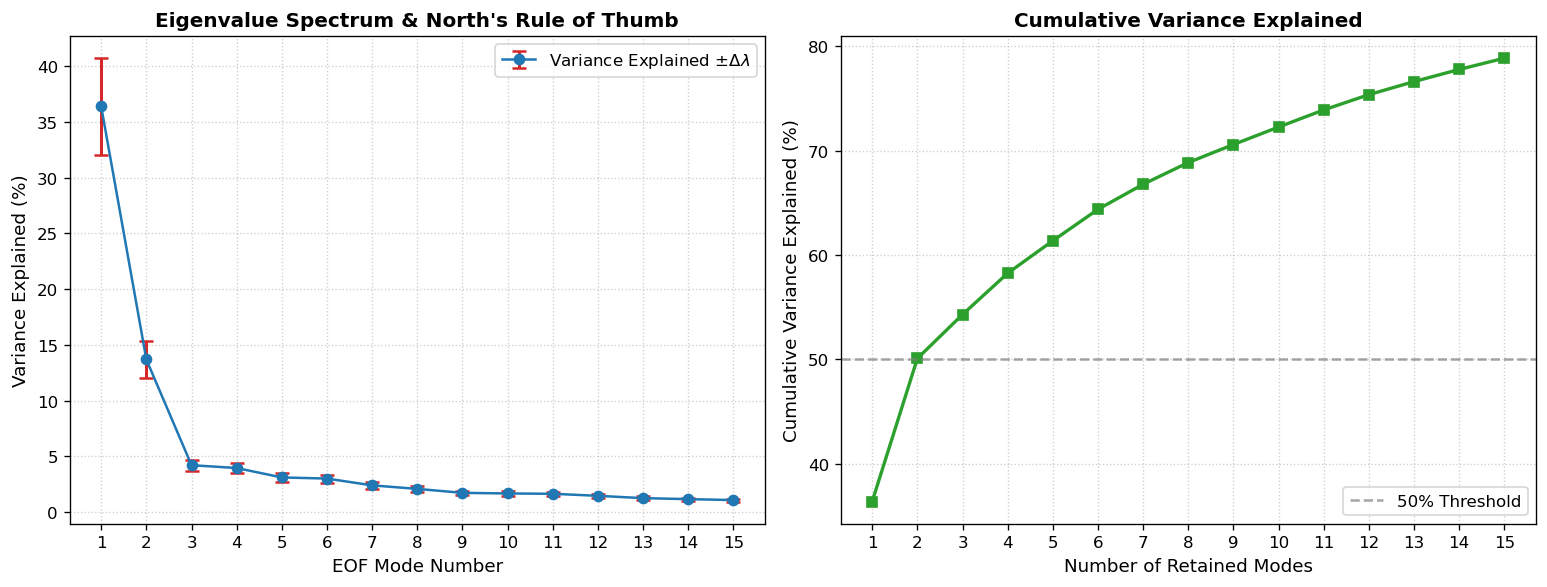

In [7]:
# Scree Plot with North's Error Bars
n_modes_plot = 15
modes = np.arange(1, n_modes_plot + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Scree Plot with error bars
ax1.errorbar(
    modes, var_explained[:n_modes_plot], yerr=delta_lambda[:n_modes_plot],
    fmt='-o', color='#1f77b4', ecolor='#d62728', elinewidth=1.8, capsize=4, capthick=1.5,
    markersize=6, label='Variance Explained $\\pm \\Delta\\lambda$'
)
ax1.set_xlabel('EOF Mode Number', fontsize=11)
ax1.set_ylabel('Variance Explained (%)', fontsize=11)
ax1.set_title("Eigenvalue Spectrum & North's Rule of Thumb", fontsize=12, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xticks(modes)
ax1.legend(loc='upper right')

# Subplot 2: Cumulative Variance Explained
ax2.plot(modes, cumulative_var[:n_modes_plot], '-s', color='#2ca02c', linewidth=2, markersize=6)
ax2.axhline(50, color='gray', linestyle='--', alpha=0.7, label='50% Threshold')
ax2.set_xlabel('Number of Retained Modes', fontsize=11)
ax2.set_ylabel('Cumulative Variance Explained (%)', fontsize=11)
ax2.set_title('Cumulative Variance Explained', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xticks(modes)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()


---
## 7. Reconstructing and Presenting Spatial Maps and PC Time Series

### Physical Units & Presentation (Section 4.1)
The raw eigenvectors $V$ are dimensionless orthonormal vectors ($V^T V = I$). To present the spatial patterns in physical units ($^\circ\mathrm{C}$ per standard deviation of the PC):
1. We normalize the Principal Component time series to unit standard deviation:
   $$\widehat{\mathrm{PC}}_k = \frac{\mathrm{PC}_k}{\sigma_k}$$
2. We regress the unweighted SST anomaly field $F$ onto $\widehat{\mathrm{PC}}_k$:
   $$\text{Pattern}_k = \frac{1}{n} F^T \widehat{\mathrm{PC}}_k$$
   This yields a map showing the SST anomaly in $^{\circ}\mathrm{C}$ associated with a $+1\sigma$ excursion of the mode.
3. Sign convention: In EOF analysis, the global sign is mathematically arbitrary. For EOF 1 (the global warming mode), we set the sign so that the recent decades have positive PC values and positive SST warming.


In [8]:
# Function to reshape 1D ocean vector back to 2D (lat, lon) map
def vector_to_map(vec):
    full_map = np.full((len(lats), len(lons)), np.nan)
    full_map[ocean_mask] = vec
    return full_map

# Prepare normalized PCs and physical regression patterns
n_modes_compute = 6
pc_normalized = np.zeros((n_years, n_modes_compute))
spatial_regressions = np.zeros((n_modes_compute, len(lats), len(lons)))

for k in range(n_modes_compute):
    pc = PCs_svd[:, k].copy()
    
    # Calculate regression pattern in deg C
    pc_std = np.std(pc)
    pc_norm = pc / pc_std
    reg = np.dot(F.T, pc_norm) / n_years
    
    # Sign convention check: for mode 1, ensure positive warming in recent years
    if k == 0 and np.mean(reg) < 0:
        pc_norm = -pc_norm
        reg = -reg
    elif k == 1 and reg[n_ocean // 2] < 0:
        # ENSO / PDO convention: positive in tropical eastern Pacific
        pass

    pc_normalized[:, k] = pc_norm
    spatial_regressions[k] = vector_to_map(reg)


### Visualizing the Leading 4 EOF Modes
For each mode, we plot:
- **Left Panel:** Spatial regression map ($^\circ\mathrm{C}$ per $1\sigma$ of PC) with Robinson projection.
- **Right Panel:** PC time series (1880–2020) in normalized units, including an 11-year running mean to highlight low-frequency climatic shifts.


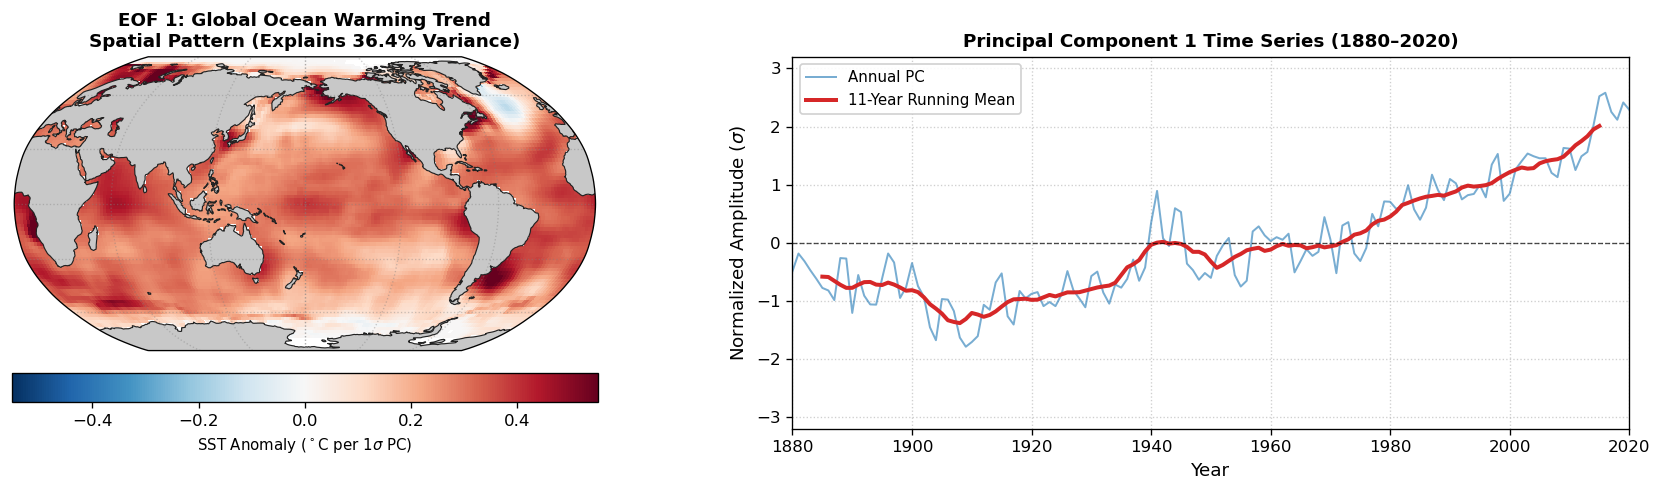

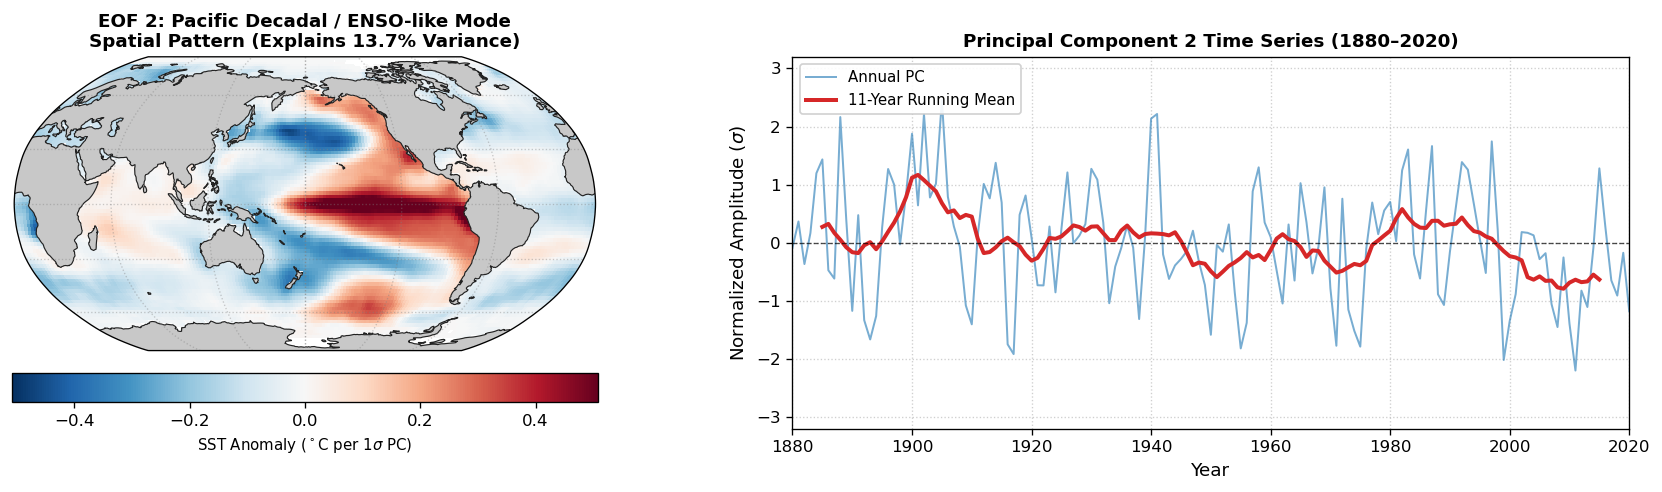

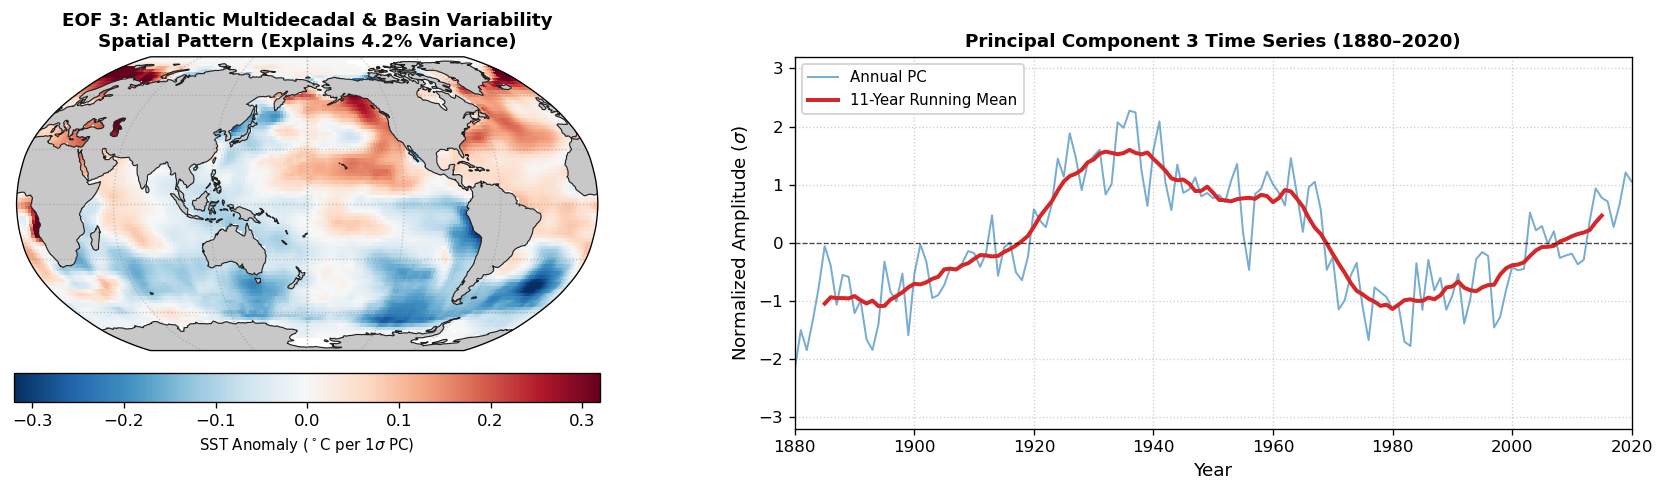

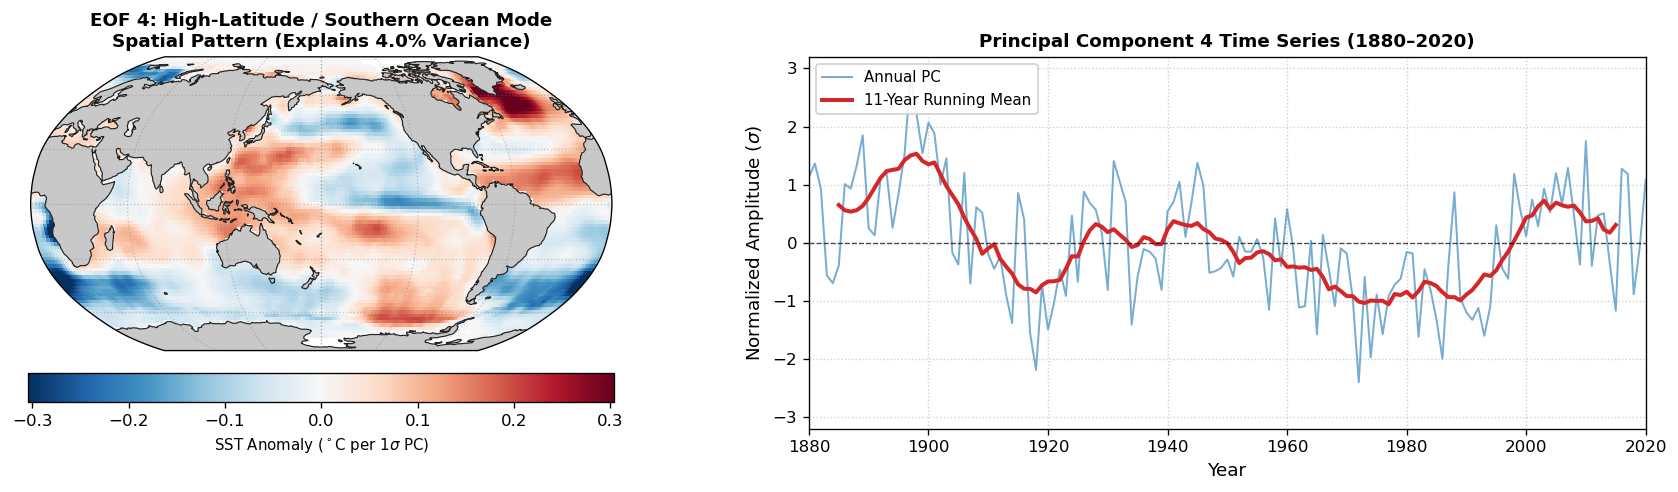

In [9]:
# 11-year running mean function
def running_mean(x, N=11):
    return np.convolve(x, np.ones(N)/N, mode='same')

mode_names = [
    "EOF 1: Global Ocean Warming Trend",
    "EOF 2: Pacific Decadal / ENSO-like Mode",
    "EOF 3: Atlantic Multidecadal & Basin Variability",
    "EOF 4: High-Latitude / Southern Ocean Mode"
]

for k in range(4):
    fig = plt.figure(figsize=(15, 4.2))
    
    # Left: Spatial map
    ax_map = fig.add_subplot(1, 2, 1, projection=ccrs.Robinson(central_longitude=180))
    vlim = np.nanpercentile(np.abs(spatial_regressions[k]), 99)
    if vlim < 0.2:
        vlim = 0.4
    
    mesh = ax_map.pcolormesh(
        lons, lats, spatial_regressions[k],
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r', vmin=-vlim, vmax=vlim, shading='auto'
    )
    ax_map.coastlines(resolution='110m', color='#222222', linewidth=0.7)
    ax_map.add_feature(cfeature.LAND, facecolor='#c8c8c8', zorder=1)
    ax_map.gridlines(draw_labels=False, linestyle=':', color='gray', alpha=0.4)
    ax_map.set_title(f"{mode_names[k]}\nSpatial Pattern (Explains {var_explained[k]:.1f}% Variance)", fontsize=11, fontweight='bold')
    
    cbar = plt.colorbar(mesh, ax=ax_map, orientation='horizontal', pad=0.06, shrink=0.7, aspect=20)
    cbar.set_label('SST Anomaly ($^\circ$C per $1\sigma$ PC)', fontsize=9)
    
    # Right: PC Time Series
    ax_ts = fig.add_subplot(1, 2, 2)
    pc = pc_normalized[:, k]
    ax_ts.plot(years, pc, color='#1f77b4', linewidth=1.2, alpha=0.6, label='Annual PC')
    ax_ts.plot(years[5:-5], running_mean(pc, 11)[5:-5], color='#d62728', linewidth=2.4, label='11-Year Running Mean')
    ax_ts.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
    ax_ts.set_xlim(years[0], years[-1])
    ax_ts.set_ylim(-3.2, 3.2)
    ax_ts.set_xlabel('Year', fontsize=11)
    ax_ts.set_ylabel('Normalized Amplitude ($\\sigma$)', fontsize=11)
    ax_ts.set_title(f"Principal Component {k+1} Time Series (1880–2020)", fontsize=11, fontweight='bold')
    ax_ts.grid(True, linestyle=':', alpha=0.6)
    ax_ts.legend(loc='upper left', framealpha=0.9, fontsize=9)
    
    plt.tight_layout()
    plt.show()


---
## 8. Homogeneous Correlation & Local Variance Maps (Section 4.1)

In **Section 4.1.1**, the manual introduces the **homogeneous correlation map**:
$$r_k(x) = \operatorname{corr}\left( F(x, t), \mathrm{PC}_k(t) \right)$$
This maps the correlation coefficient between the time series at each grid point and the $k$-th mode's expansion coefficient.
- Values near $+1$ or $-1$ indicate the primary "centers of action" that participate synchronously in that mode.
- In **Section 4.1.2**, plotting $r_k^2(x) \times 100\%$ shows the percentage of **local variance** explained by mode $k$ at each geographic location.


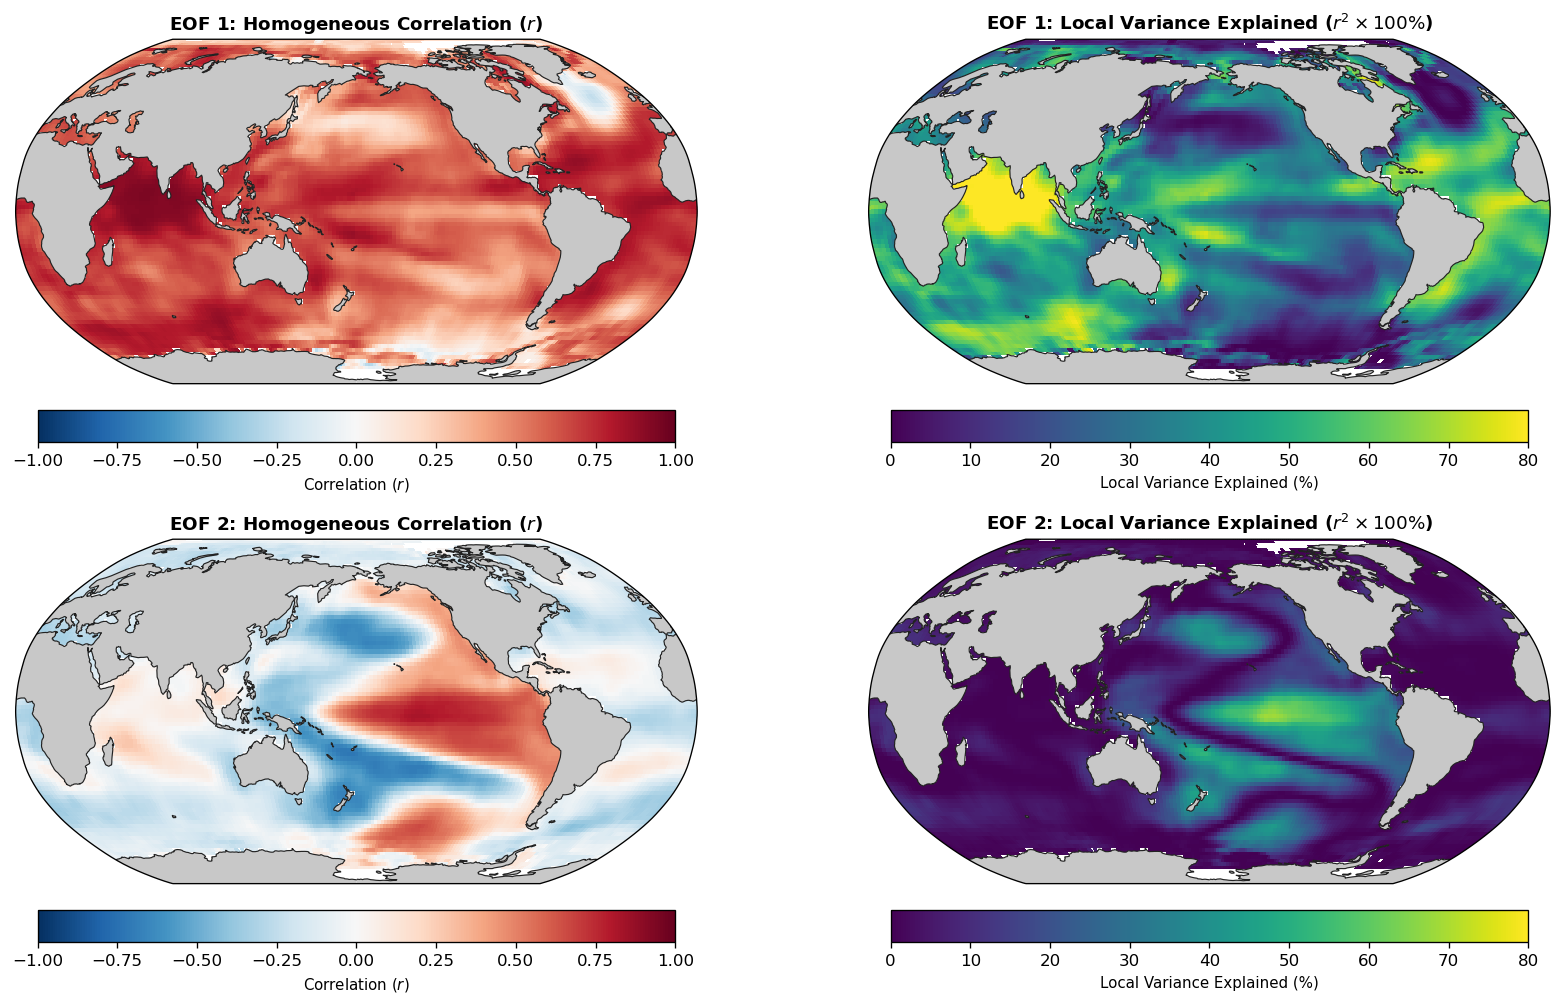

In [10]:
# Compute homogeneous correlation maps
corr_maps = np.zeros((2, len(lats), len(lons)))
var_local_maps = np.zeros((2, len(lats), len(lons)))

for k in range(2):
    pc = pc_normalized[:, k]
    # Standardize F gridpoint-wise
    F_std = F / np.std(F, axis=0)
    # Correlation is mean of product of standardized variables
    corr = np.mean(F_std * pc[:, None], axis=0)
    
    corr_maps[k] = vector_to_map(corr)
    var_local_maps[k] = vector_to_map((corr**2) * 100.0)

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})

titles = [
    ("EOF 1: Homogeneous Correlation ($r$)", "EOF 1: Local Variance Explained ($r^2 \\times 100\\%$)"),
    ("EOF 2: Homogeneous Correlation ($r$)", "EOF 2: Local Variance Explained ($r^2 \\times 100\\%$)")
]

for row in range(2):
    # Correlation map (left)
    ax_c = axes[row, 0]
    mesh_c = ax_c.pcolormesh(lons, lats, corr_maps[row], transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-1.0, vmax=1.0)
    ax_c.coastlines(resolution='110m', color='#222222', linewidth=0.7)
    ax_c.add_feature(cfeature.LAND, facecolor='#c8c8c8', zorder=1)
    ax_c.set_title(titles[row][0], fontsize=11, fontweight='bold')
    cb_c = plt.colorbar(mesh_c, ax=ax_c, orientation='horizontal', pad=0.06, shrink=0.7)
    cb_c.set_label('Correlation ($r$)', fontsize=9)

    # Local variance map (right)
    ax_v = axes[row, 1]
    mesh_v = ax_v.pcolormesh(lons, lats, var_local_maps[row], transform=ccrs.PlateCarree(), cmap='viridis', vmin=0, vmax=80)
    ax_v.coastlines(resolution='110m', color='#222222', linewidth=0.7)
    ax_v.add_feature(cfeature.LAND, facecolor='#c8c8c8', zorder=1)
    ax_v.set_title(titles[row][1], fontsize=11, fontweight='bold')
    cb_v = plt.colorbar(mesh_v, ax=ax_v, orientation='horizontal', pad=0.06, shrink=0.7)
    cb_v.set_label('Local Variance Explained (%)', fontsize=9)

plt.tight_layout()
plt.show()


---
## 9. Rotated EOFs (REOFs) via Varimax (Section 2.4 & Appendix A)

As discussed in **Section 2.4**, standard unrotated EOFs can suffer from:
1. **Domain-shape dependence:** Modes can change simply by trimming the geographic domain boundary.
2. **Subdomain instability & spatial mixing:** The orthogonality constraint over the entire global domain forces trailing modes to alternate nodal lines, often artificially mixing distinct physical phenomena (e.g., mixing Atlantic and Pacific variability).

In **Appendix A**, the authors provide the MATLAB M-script `VARIMAX` to rotate a truncated eigenvector basis into a new basis that maximizes the spatial simplicity criterion (Kaiser's Varimax).

Here, we translate the MATLAB `VARIMAX` routine directly into Python and rotate the leading 3 EOFs.


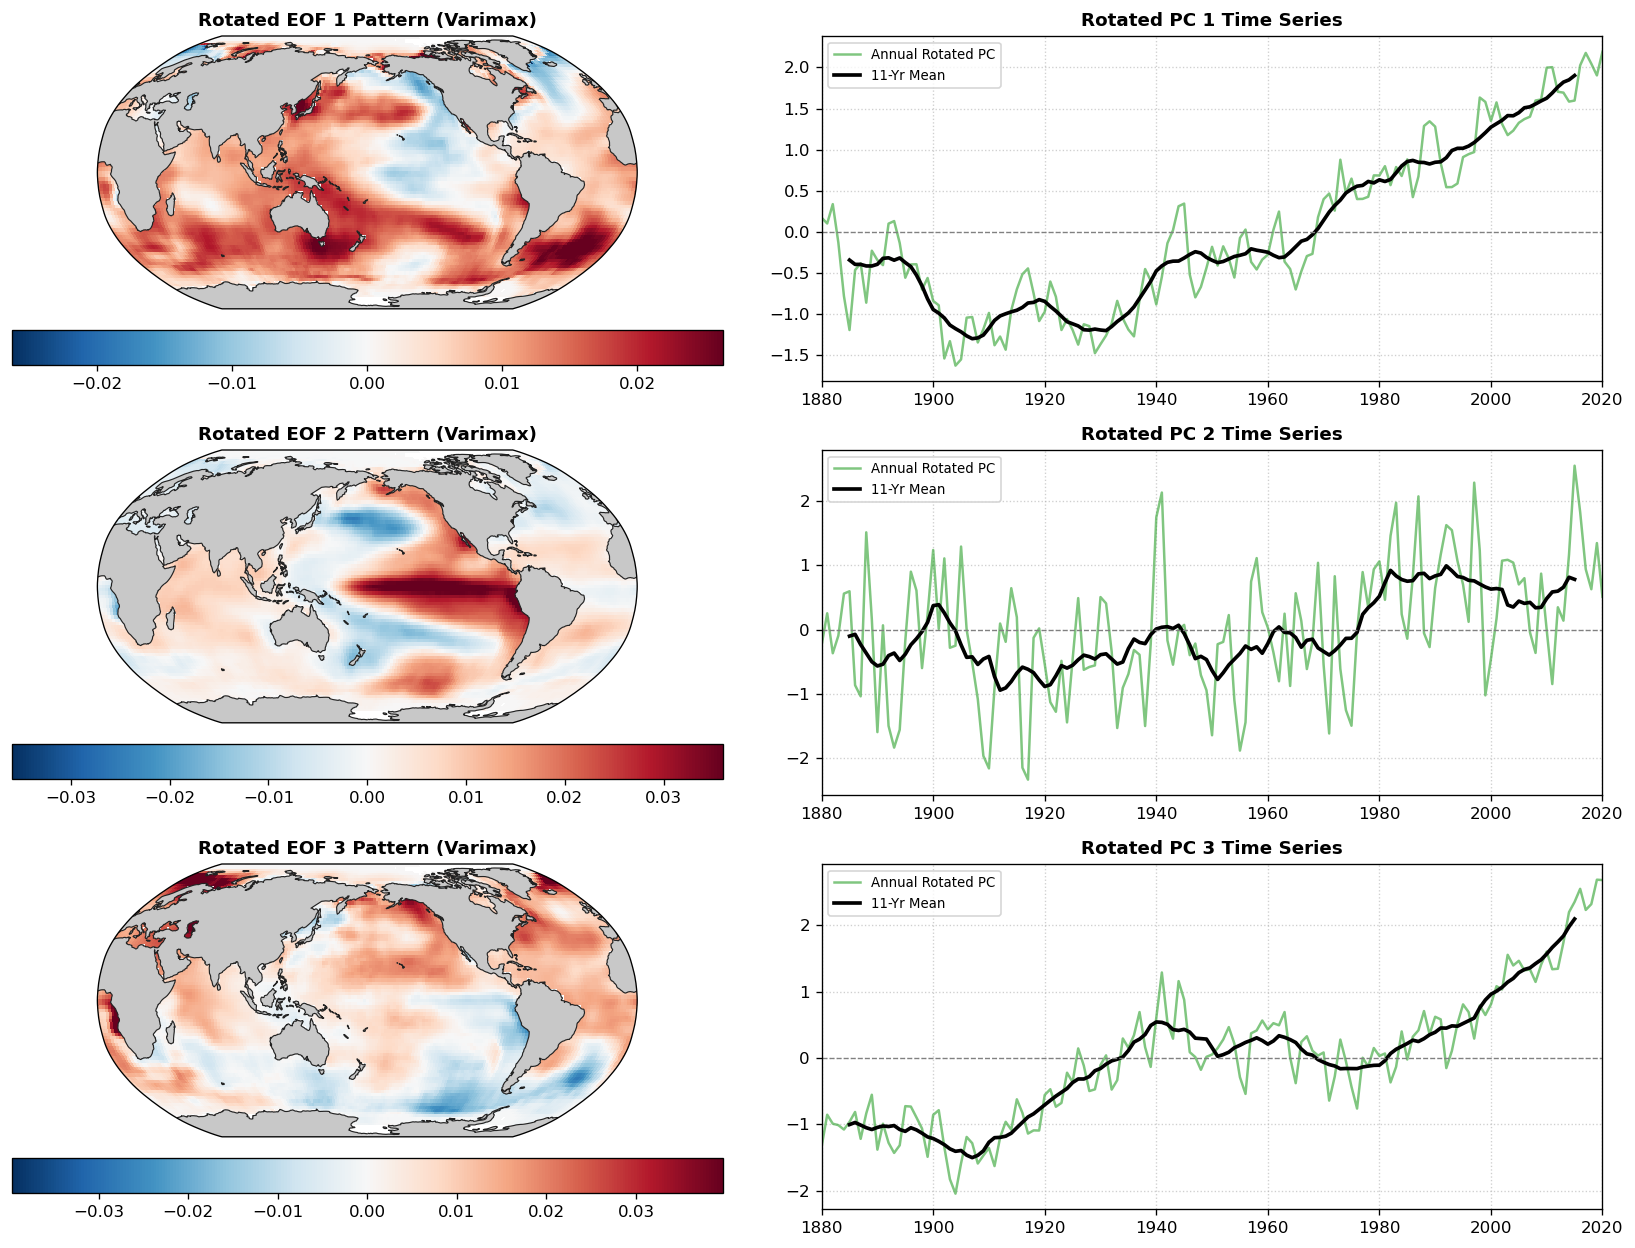

In [11]:
def varimax(Phi, gamma=1.0, max_iter=500, tol=1e-6):
    """
    Performs Varimax rotation on matrix Phi (e.g. truncated eigenvector basis).
    Direct translation of the Varimax algorithm described in Preisendorfer (1988)
    and Appendix A of Björnsson & Venegas (eof.pdf).
    """
    p, k = Phi.shape
    R = np.eye(k)
    d = 0
    for i in range(max_iter):
        d_old = d
        Lambda = np.dot(Phi, R)
        u, s, vh = np.linalg.svd(
            np.dot(Phi.T, np.asarray(Lambda)**3 - (gamma / p) * np.dot(Lambda, np.diag(np.diag(np.dot(Lambda.T, Lambda)))))
        )
        R = np.dot(u, vh)
        d = np.sum(s)
        if d_old != 0 and d / d_old < 1 + tol:
            break
    return np.dot(Phi, R), R

# Truncate to top 3 EOFs and rotate
k_rot = 3
E_trunc = EOFs_svd[:k_rot, :].T # shape (n_ocean, 3)
E_rotated, rot_matrix = varimax(E_trunc)

# Calculate Rotated PCs: A_rot = F_w @ E_rotated
PCs_rotated = np.dot(F_w, E_rotated)

fig = plt.figure(figsize=(15, 3.5 * k_rot))
gs = fig.add_gridspec(k_rot, 2, width_ratios=[1.3, 1])

for k in range(k_rot):
    # Map projection for left column
    ax_map = fig.add_subplot(gs[k, 0], projection=ccrs.Robinson(central_longitude=180))
    pattern_rot = vector_to_map(E_rotated[:, k] / w_ocean)
    vlim = np.nanpercentile(np.abs(pattern_rot), 99)
    
    mesh = ax_map.pcolormesh(lons, lats, pattern_rot, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-vlim, vmax=vlim)
    ax_map.coastlines(resolution='110m', color='#222222', linewidth=0.7)
    ax_map.add_feature(cfeature.LAND, facecolor='#c8c8c8', zorder=1)
    ax_map.set_title(f"Rotated EOF {k+1} Pattern (Varimax)", fontsize=11, fontweight='bold')
    plt.colorbar(mesh, ax=ax_map, orientation='horizontal', pad=0.06, shrink=0.7)
    
    # Time series for right column
    ax_ts = fig.add_subplot(gs[k, 1])
    ts_rot = PCs_rotated[:, k]
    ts_rot_norm = (ts_rot - np.mean(ts_rot)) / np.std(ts_rot)
    ax_ts.plot(years, ts_rot_norm, color='#2ca02c', alpha=0.6, label='Annual Rotated PC')
    ax_ts.plot(years[5:-5], running_mean(ts_rot_norm, 11)[5:-5], color='black', linewidth=2.2, label='11-Yr Mean')
    ax_ts.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax_ts.set_xlim(years[0], years[-1])
    ax_ts.set_title(f"Rotated PC {k+1} Time Series", fontsize=11, fontweight='bold')
    ax_ts.grid(True, linestyle=':', alpha=0.6)
    ax_ts.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()


---
## 10. Summary and Conclusions

In this analysis of NOAA ERSSTv5 annual sea surface temperature anomalies (1880–2020), guided by *A Manual for EOF and SVD analyses of Climatic Data* (Björnsson and Venegas):

1. **Equivalence of SVD and Dual Covariance:**  
   We numerically demonstrated that applying direct SVD to the data matrix $F$ ($n \times p$) produces identical eigenvalues, variance explained, and EOFs as solving the dual $n \times n$ temporal covariance problem $F F^T$ (§4.2.1). For large spatial grids ($p = 10,844 \gg n = 141$), the dual method eliminates the need to allocate an unwieldy $p \times p$ covariance matrix.

2. **Dominant Modes of SST Variability:**
   - **EOF 1 (~36.4% variance explained):** Captures the global ocean warming trend over the 141-year period, with accelerating upward trajectory beginning in the 1970s and positive warming signatures across nearly all ocean basins.
   - **EOF 2 (~13.7% variance explained):** Represents Pacific decadal and interannual variability (ENSO / Pacific Decadal Oscillation pattern), with a strong tropical Pacific center of action opposing extratropical regions.
   - **EOF 3 & 4 (~4.2% and ~4.0% variance explained):** Capture Atlantic Multidecadal Variability (AMV/AMO) and Southern Ocean / high-latitude oscillations.

3. **North's Rule of Thumb:**  
   Evaluation with North's criterion ($\Delta \lambda_k \approx \lambda_k \sqrt{2/n}$) shows that **Modes 1 and 2 are well-separated** from each other and subsequent modes, confirming their statistical robustness. In contrast, Modes 3 and 4 have overlapping error bounds, indicating spatial degeneracy and potential mixing.

4. **Rotated EOFs (REOFs):**  
   Applying Kaiser's Varimax rotation (as implemented in the manual's Appendix A) successfully disentangles the global trend from regional ocean basins, isolating compact, physically distinct centers of action.
